# Use case: Copernicus DEM on a small area

Earth Data Hub offers an innovative and super-efficient way to access data.

Here we present how to best access the service in the simplest use case: getting the elevation of a small area, e.g. the surroundings of Rome. Note that we will be using the Copernicus DEM GLO-30 dataset, which covers the whole globe at 1 arc-second resolution (about 30m) and is 3.4TB in size.

We show two best practices: with Python and Xarray, to select and plot the data, and with the GDAL command line tools, to crop and reproject it to GeoTIFF files.

**GIS experts who know GDAL, but not Xarray**, can set up the environment and then skip straight to the _Crop the DEM with GDAL_ section.

## Setup the environment

**If you haven't done it already, follow the [Getting started notebook](./00-getting-started.ipynb) to setup your environment and DestinE credentials.**

## Access the DEM with Xarray

The best practice for accessing data from the Earth Data Hub with Xarray comprises the following steps:
1. open the dataset using the code snippet found on the [Copernicus DEM GLO-30 dataset page](https://earthdatahub.destine.eu/collections/copernicus-dem/datasets/GLO-30)
2. select the variable
3. select the area of interest (optionally aligning it on chunk boundaries)

### Open the dataset

The following assumes you set up your EDH API key in your _netrc_ file.

In [1]:
import xarray as xr

dem_dataset = xr.open_dataset(
    "https://data.earthdatahub.destine.eu/copernicus-dem/GLO-30-v1.zarr",
    storage_options={"client_kwargs": {"trust_env": True}},
    chunks={},
    engine="zarr",
    mask_and_scale=False,
    decode_coords="all",
)
dem_dataset

<xarray.Dataset> Size: 3TB
Dimensions:      (lat: 648000, lon: 1296000)
Coordinates:
  * lat          (lat) float64 5MB 90.0 90.0 90.0 90.0 ... -90.0 -90.0 -90.0
  * lon          (lon) float64 10MB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
    spatial_ref  int64 8B ...
Data variables:
    dsm          (lat, lon) float32 3TB dask.array<chunksize=(1800, 3600), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.12
    title:        Copernicus DEM GLO-30
    history:      2026-10-01: converted from s3://edh-root/copernicus-dem/GLO...

### Select the variable

Note that all operations are lazy, that is they are not applied to the whole 3.4TB of data, but are just recorded for later use. Download and computations are only done when requested.

In [2]:
dsm_world = dem_dataset.dsm
dsm_world

<xarray.DataArray 'dsm' (lat: 648000, lon: 1296000)> Size: 3TB
dask.array<open_dataset-dsm, shape=(648000, 1296000), dtype=float32, chunksize=(1800, 3600), chunktype=numpy.ndarray>
Coordinates:
  * lat          (lat) float64 5MB 90.0 90.0 90.0 90.0 ... -90.0 -90.0 -90.0
  * lon          (lon) float64 10MB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
    spatial_ref  int64 8B ...
Attributes:
    long_name:      height of model surface above the EGM2008 geoid
    standard_name:  surface_altitude
    units:          m
    _FillValue:     0.0
    AREA_OR_POINT:  Point
    positive:       up
    _CRS:           {'url': 'http://www.opengis.net/def/crs/EPSG/0/9518'}

### Select the area of interest

For example we are interested in the area of Rome.

This a very convenient example as:
* it is a large enough area to be more interesting than the elevation of a single point,
* it is small enough to fit a single Zarr chunk, so the notebook can be run even with a slow internet connection,
* when plotted it is easy to identify even without adding coastlines and country borders: the Tiber valley crossing Rome and the volcanic Alban Hills with their two crater lakes in the bottom right.

In [3]:
aoi_selection = {
    "lat": slice(42, 41.65),  # NOTE: latitudes run from north to south
    "lon": slice(12.3, 12.8),
}
dsm_aoi = dsm_world.sel(aoi_selection)
dsm_aoi

<xarray.DataArray 'dsm' (lat: 1261, lon: 1801)> Size: 9MB
dask.array<getitem, shape=(1261, 1801), dtype=float32, chunksize=(1261, 1801), chunktype=numpy.ndarray>
Coordinates:
  * lat          (lat) float64 10kB 42.0 42.0 42.0 42.0 ... 41.65 41.65 41.65
  * lon          (lon) float64 14kB 12.3 12.3 12.3 12.3 ... 12.8 12.8 12.8 12.8
    spatial_ref  int64 8B ...
Attributes:
    long_name:      height of model surface above the EGM2008 geoid
    standard_name:  surface_altitude
    units:          m
    _FillValue:     0.0
    AREA_OR_POINT:  Point
    positive:       up
    _CRS:           {'url': 'http://www.opengis.net/def/crs/EPSG/0/9518'}

Note that the data size is now much smaller, we went from 3.4TB for global data to 9MB of our small area of interest.

We plot the map of the elevation to double check that the selection is correct:

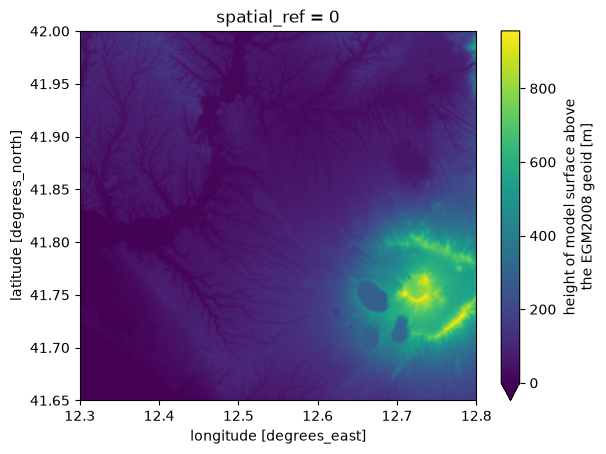

In [4]:
dsm_aoi.plot(vmin=0)

### Optional: align the area of interest on chunk boundaries

This a pro move and you can skip it.

When accessing the data in Zarr you always download whole chunks, even if you are only interested in part of them. In the case of Copernicus DEM GLO-30 the spatial chunks are `(1800, 3600)` in size, that is 0.5° by 1°, and even if you can read above that your DataArray is only 9MB of data you are most probably downloading more data and then throwing a part of it away.

You can use the following (not very nice) code to grow your area of interest to the boundaries of the Zarr chunks, so you use all the data you download. Note that now you also have the size of the data that would be downloaded if it was not compressed (the data is in fact compressed so actual download is smaller).

In [5]:
def align_indexer(step, indexer):
    if not isinstance(indexer, slice):
        return indexer
    assert indexer.step is None
    start = indexer.start // step * step if indexer.start else indexer.start
    stop = ((indexer.stop - 1) // step + 1) * step if indexer.stop else indexer.stop
    return slice(start, stop)


query_results = xr.core.indexing.map_index_queries(
    dsm_world, indexers=aoi_selection, method=None, tolerance=None
)
print(query_results.dim_indexers)

chunk_sizes = {"lat": 1800, "lon": 3600}
aoi_iselection = {
    dim: align_indexer(chunk_sizes[dim], query_results.dim_indexers[dim])
    for dim in query_results.dim_indexers
}
print(aoi_iselection)

dsm_aoi = dsm_world.isel(aoi_iselection)
dsm_aoi

{'lat': slice(172800, 174061, None), 'lon': slice(692280, 694081, None)}
{'lat': slice(172800, 174600, None), 'lon': slice(691200, 694800, None)}


<xarray.DataArray 'dsm' (lat: 1800, lon: 3600)> Size: 26MB
dask.array<getitem, shape=(1800, 3600), dtype=float32, chunksize=(1800, 3600), chunktype=numpy.ndarray>
Coordinates:
  * lat          (lat) float64 14kB 42.0 42.0 42.0 42.0 ... 41.5 41.5 41.5 41.5
  * lon          (lon) float64 29kB 12.0 12.0 12.0 12.0 ... 13.0 13.0 13.0 13.0
    spatial_ref  int64 8B ...
Attributes:
    long_name:      height of model surface above the EGM2008 geoid
    standard_name:  surface_altitude
    units:          m
    _FillValue:     0.0
    AREA_OR_POINT:  Point
    positive:       up
    _CRS:           {'url': 'http://www.opengis.net/def/crs/EPSG/0/9518'}

So, the whole chunk is really 26MB, not 9MB.

Let's have a look at the area of the whole chunk.

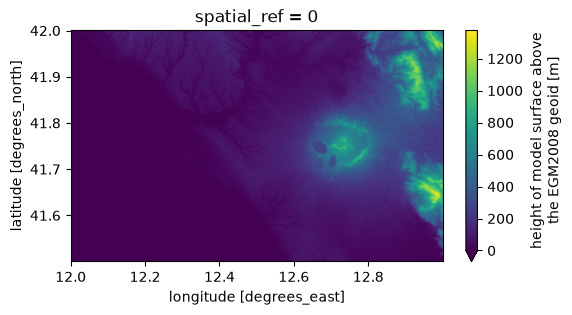

In [6]:
dsm_aoi.plot(figsize=(6, 3), vmin=0)

Great! A single 1800x3600 chunk covers Rome, the whole Alban Hills and the first ridges of the Apennines to the east.

## Crop the DEM with GDAL

Unlike most Earth Data Hub datasets, the Copernicus DEM can also be read directly by GDAL 3.8 or newer, so you can use the familiar command line tools instead of Python:
* the whole DEM is a single Zarr store, with no tiles to mosaic: GDAL opens it as one 1296000 x 648000 raster in WGS 84 + EGM2008 height (EPSG:9518),
* GDAL reads your EDH API key from the same _netrc_ file, so there is nothing else to set up,
* only the Zarr chunks that intersect your window are downloaded.

GDAL is not part of the Python environment of this repo, install it with your package manager of choice, e.g. `brew install gdal` or `conda install -c conda-forge gdal`.

### Crop with `gdal_translate`

We extract the same area of interest as above to a GeoTIFF file. Note that `-projwin` takes the upper left and lower right corners, that is `ulx uly lrx lry`.

In [7]:
%%bash

gdal_translate \
    -projwin 12.3 42 12.8 41.65 \
    'ZARR:"/vsicurl/https://data.earthdatahub.destine.eu/copernicus-dem/GLO-30-v1.zarr":/dsm' \
    rome-dsm-wgs84.tif

Input file size is 1296000, 648000
0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:15.


### Crop and reproject with `gdalwarp`

`gdalwarp` crops and reprojects in one step, here to UTM zone 33N with 20m pixels. Three details are worth noting:
* the target CRS is `EPSG:32633+3855`, that is UTM zone 33N plus EGM2008 height: with plain `EPSG:32633` GDAL converts the heights to the WGS 84 ellipsoid, adding about 48m around Rome,
* the pixel size `-tr` is 20m, finer than the source: at the latitude of Rome the 1 arc-second pixels are about 31m north-south, but only 23m east-west, so 30m pixels would interpolate badly,
* the extent `-te` (`xmin ymin xmax ymax` in the target CRS) is slightly inside the area above, so it still fits in a single Zarr chunk.

In [8]:
%%bash

gdalwarp -overwrite \
    -t_srs EPSG:32633+3855 \
    -te 276000 4614000 318000 4650000 \
    -tr 20 20 \
    -r bilinear \
    'ZARR:"/vsicurl/https://data.earthdatahub.destine.eu/copernicus-dem/GLO-30-v1.zarr":/dsm' \
    rome-dsm-utm33n.tif

Creating output file that is 2100P x 1800L.
Using internal nodata values (e.g. 0) for image ZARR:"/vsicurl/https://data.earthdatahub.destine.eu/copernicus-dem/GLO-30-v1.zarr":/dsm.
Copying nodata values from source ZARR:"/vsicurl/https://data.earthdatahub.destine.eu/copernicus-dem/GLO-30-v1.zarr":/dsm to destination rome-dsm-utm33n.tif.
Processing dsm [1/1] : 0...10...20...30...40...50...60...70...80...90...100 - done in 00:00:11.


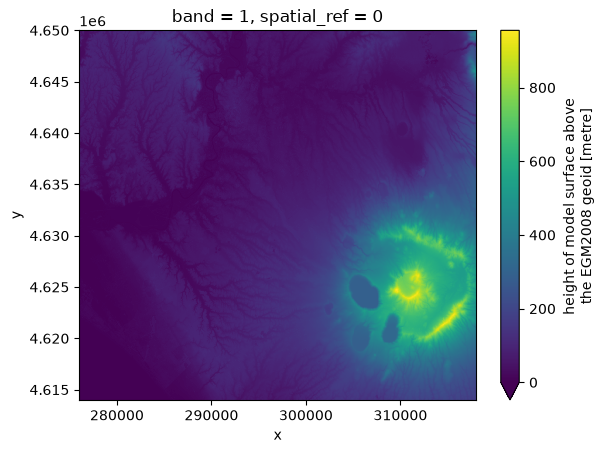

In [9]:
import xarray as xr

dsm_utm = xr.open_dataarray("rome-dsm-utm33n.tif", mask_and_scale=False)
dsm_utm.sel(band=1).plot(vmin=0, xticks=range(280000, 320000, 10000))